## Output Analysis Development
Use this notebook for initial assessment of model output and development of automated analysis scripts.

In [1]:
# Run settings
site = 'Tres Ritos'
namelist = 'ghelaps'
forcing_str = '01011010'
forcing_version = '0.10.1'
version = '0008'
isAlpine = False

In [2]:
# Load environmental variables if on Alpine, otherwise they should be stored
import os

# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/scratch/alpine/ccox1@xsede.org/model_data/input/forcing/'

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [4]:
forcing = LM4Forcing(site=site, forcing_string=forcing_str, version=forcing_version, spinup=False)

In [5]:
forcing_vars = forcing.get_variables()
forcing_vars.head()

,dimensions,long_name,units
Tair,"(time, latitude, longitude)",Near-surface air Temperature,K
Qair,"(time, latitude, longitude)",Near-surface specific humidity,kg/kg
Psurf,"(time, latitude, longitude)",Surface Pressure,Pa
Rainf,"(time, latitude, longitude)",Rainfall rate,kg/m2/s
Snowf,"(time, latitude, longitude)",Snowfall rate,kg/m2/s


In [6]:
model = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)

In [7]:
daily_vars = model.get_variables(diag='land_daily')

In [8]:
monthly_vars = model.get_variables(diag='land_month')

In [9]:
snotel = PNNLSnotel(site, os.environ['SNOTEL_PATH'])
snotel.load_data()

In [10]:
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)

In [11]:
snotel_data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2006-09-21,25.994444,NaN,NaN,NaN,NaN
2006-09-22,16.266667,-0.900000,2.533333,NaN,NaN
2006-09-23,15.694444,-2.044444,3.105556,NaN,NaN
2006-09-24,26.566667,-6.622222,3.677778,NaN,NaN
2006-09-25,36.866667,-4.333333,5.394444,NaN,NaN


In [12]:
snotel_data.loc[snotel_data['swe_mm']>0,'swe_mm'].sort_values().head()

Date
2006-11-28    2.54
2010-10-24    2.54
2007-12-05    2.54
2007-12-06    2.54
2007-12-07    2.54
Name: swe_mm, dtype: float64

### Snow
Compare modeled snow output to observed and precipitation and temperature.

In [13]:
model_snow = model.get_data(['snow','snow_depth'],'land_daily')

In [14]:
# Get range of dates for plotting
start_date = model_snow.index[0]
end_date = model_snow.index[-1]

In [15]:
Tair = forcing.get_data('Tair')
Tair = Tair - 273.15  # Convert from Kelvin to Celsius
Tair_max = Tair.resample('D').max()
Tair_min = Tair.resample('D').min()

In [16]:
Tair.head()

time
2006-10-01 06:00:00    4.860169
2006-10-01 07:00:00    4.185749
2006-10-01 08:00:00    3.531165
2006-10-01 09:00:00    2.856745
2006-10-01 10:00:00    2.360847
Name: Tair, dtype: float64

In [17]:
Tair_flags = forcing.get_flags('Tair')
#Tair_flags['1992-09-30':'1992-12'].head(20)

In [18]:
# Extract precipitation and recombine
snowfall = forcing.get_data('Snowf')
rainfall = forcing.get_data('Rainf')

precipdf = pd.DataFrame({'snowf':snowfall,'rainf':rainfall})
precipdf['combined'] = (precipdf['snowf'] + precipdf['rainf'])*3600 #Convert to hourly total kg/m2/s

In [19]:
precip_daily = precipdf['combined'].resample('1D').sum()

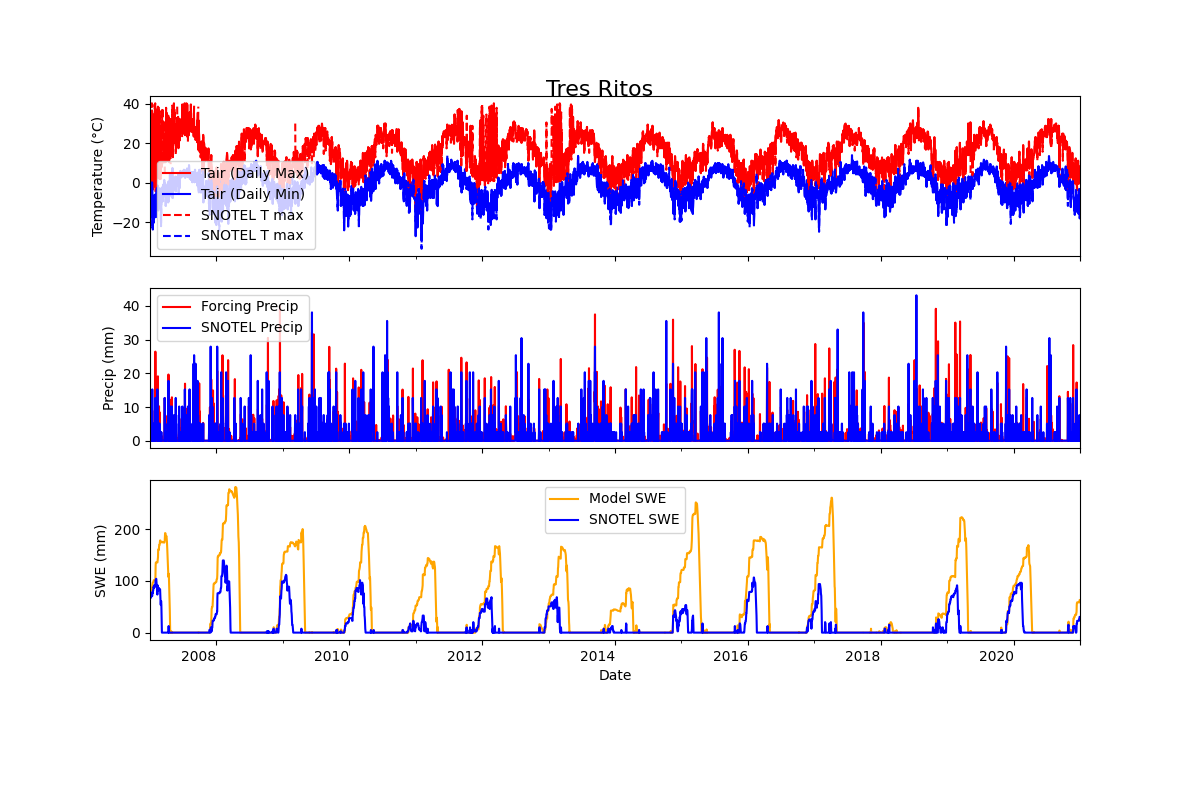

In [20]:
# Plot snow
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

Tair_max.plot(ax=ax[0], label='Tair (Daily Max)', color='red')
Tair_min.plot(ax=ax[0], label='Tair (Daily Min)', color='blue')
snotel_data.loc[start_date:end_date, 'T_max_C'].plot(ax=ax[0], label='SNOTEL T max', style='--r')
snotel_data.loc[start_date:end_date, 'T_min_C'].plot(ax=ax[0], label='SNOTEL T max', style='--b')

precip_daily.plot(ax=ax[1], label='Forcing Precip', color='red')
snotel_data.loc[start_date:end_date, 'precip_mm'].plot(ax=ax[1], label='SNOTEL Precip', color='blue')

model_snow['snow'].plot(ax=ax[2], label='Model SWE', color='orange')
snotel_data.loc[start_date:end_date, 'swe_mm'].plot(ax=ax[2], label='SNOTEL SWE', color='blue')

# Add a figure title based on site name
plt.suptitle(f'{site}', fontsize=16, y=0.9)
ax[0].set_ylabel('Temperature (°C)')
ax[1].set_ylabel('Precip (mm)')
ax[2].set_ylabel('SWE (mm)')
ax[0].legend()
ax[1].legend()
ax[2].legend()

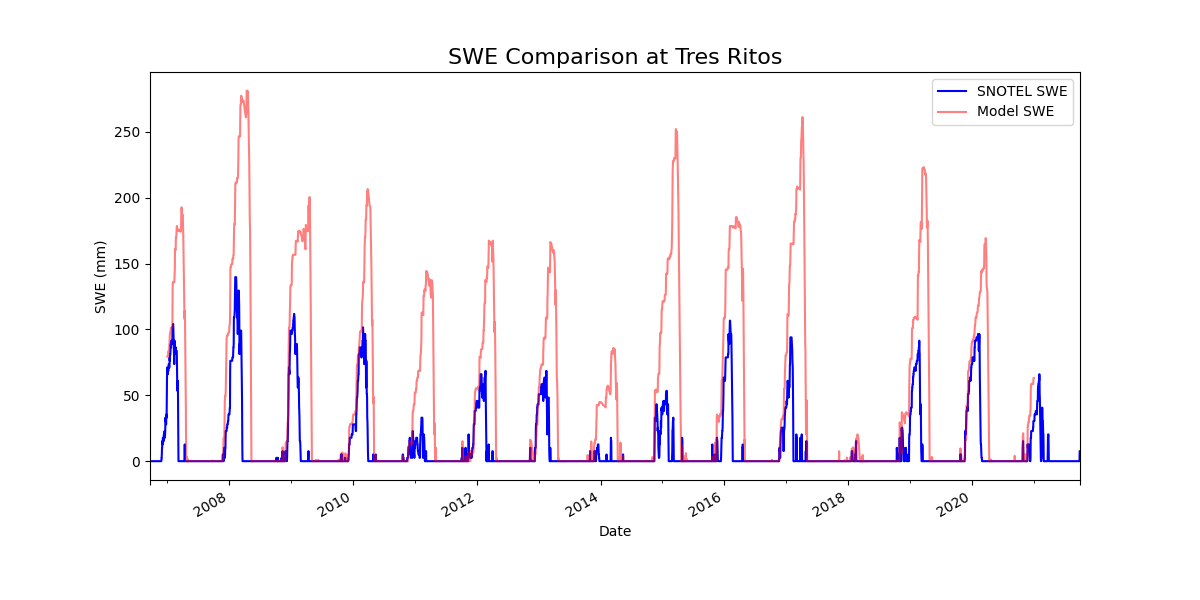

In [21]:
# Plot just showing SWE comparison, use in presentations
fig, ax = plt.subplots(figsize=(12, 6))
snotel_data.loc[:, 'swe_mm'].plot(ax=ax, label='SNOTEL SWE', color='blue')
model_snow['snow'].plot(ax=ax, label='Model SWE', color='red', alpha=0.5)
plt.title(f'SWE Comparison at {site}', fontsize=16)
ax.set_ylabel('SWE (mm)')
ax.legend()

#### RMSE Calculation

In [22]:
# Shift snotel data index by 12 hours to match model output timing
snotel_data.index = snotel_data.index + pd.Timedelta(hours=12)

In [23]:
# Combine model and snotel data
combined_df = pd.merge(model_snow, snotel_data[['swe_mm']], left_index=True, right_index=True, how='inner')

In [24]:
# Calculate the difference between model and snotel SWE
combined_df['swe_diff'] = combined_df['snow'] - combined_df['swe_mm']

In [25]:
# Calculate the RMSE, don't use first year of data to avoid spinup effects
combined_df = combined_df[combined_df.index >= (combined_df.index.min() + pd.DateOffset(years=1))]
rmse = (combined_df['swe_diff']**2).mean()**0.5
print(f'RMSE between model and SNOTEL SWE: {rmse:.2f} mm')

RMSE between model and SNOTEL SWE: 70.45 mm


In [26]:
# nRMSE
nrmse = rmse / combined_df['swe_mm'].mean()
print(f'mean SNOTEL SWE: {combined_df["swe_mm"].mean():.2f} mm')
print(f'nRMSE = {nrmse}')

mean SNOTEL SWE: 11.01 mm
nRMSE = 6.399864770842803


### Snow Days Calc

In [27]:
test = combined_df.loc['2015-10':'2016-07',['snow','swe_mm']]
print(f'SNOTEL: {test.loc[test['swe_mm'] > 5, 'swe_mm'].count()}')
print(f'Model: {test.loc[test['snow'] > 5, 'snow'].count()}')

SNOTEL: 79
Model: 171


In [28]:
#Whole dataset
print(f'SNOTEL: {combined_df.loc[combined_df['swe_mm'] > 5, 'swe_mm'].count()}')
print(f'Model: {combined_df.loc[combined_df['snow'] > 5, 'snow'].count()}')

SNOTEL: 1131
Model: 1960
